In [7]:
import pandas as pd
from sqlalchemy import text
from epo.tipdata.patstat import PatstatClient
from sqlalchemy import func, or_

# 1. Connect to PATSTAT
patstat = PatstatClient(env="PROD")  # Use "PROD" for the full database
db = patstat.orm()

In [8]:
# 2. Retrieve the available filing authorities
query = text("""
    SELECT DISTINCT appln_auth
    FROM tls201_appln
    WHERE appln_auth IS NOT NULL
      AND TRIM(appln_auth) <> ''
    ORDER BY appln_auth
""")

df_ptos = pd.read_sql(query, db.bind)

# 3. Display the complete list
print(f"Number of authorities: {len(df_ptos)}")
print(df_ptos.to_string(index=False))

Number of authorities: 208
appln_auth
        AD
        AE
        AF
        AL
        AM
        AN
        AO
        AP
        AR
        AT
        AU
        AW
        AZ
        BA
        BB
        BD
        BE
        BG
        BH
        BI
        BN
        BO
        BR
        BS
        BW
        BX
        BY
        BZ
        CA
        CD
        CG
        CH
        CI
        CL
        CM
        CN
        CO
        CR
        CS
        CU
        CW
        CX
        CY
        CZ
        DD
        DE
        DK
        DM
        DO
        DZ
        EA
        EC
        EE
        EG
        EM
        EP
        ER
        ES
        ET
        FI
        FR
        GA
        GB
        GC
        GD
        GE
        GF
        GH
        GI
        GM
        GN
        GQ
        GR
        GT
        GY
        HK
        HN
        HR
        HT
        HU
        IB
        ID
        IE
        IL
        IN
        IO
        IQ
     

In [9]:
query = text("""
    SELECT
        appln_auth,
        COUNT(*) AS application_count,
        COUNT(DISTINCT CASE
            WHEN docdb_family_id > 0 THEN docdb_family_id
        END) AS family_count,
        ROUND(
            1.0 * COUNT(CASE WHEN docdb_family_id > 0 THEN 1 END)
            / NULLIF(
                COUNT(DISTINCT CASE
                    WHEN docdb_family_id > 0 THEN docdb_family_id
                END), 0
            ), 2
        ) AS applications_per_family
    FROM tls201_appln
    WHERE appln_auth IS NOT NULL
      AND TRIM(appln_auth) <> ''
    GROUP BY appln_auth
    ORDER BY application_count DESC
""")

df_authorities = pd.read_sql(query, db.bind)

# Global totals across the selected database
totals_query = text("""
    SELECT
        COUNT(*) AS total_applications,
        COUNT(DISTINCT CASE
            WHEN docdb_family_id > 0 THEN docdb_family_id
        END) AS total_families
    FROM tls201_appln
""")

totals = pd.read_sql(totals_query, db.bind).iloc[0]

df_authorities["global_applications_pct"] = (
    100 * df_authorities["application_count"]
    / totals["total_applications"]
).round(2)

df_authorities["global_families_pct"] = (
    100 * df_authorities["family_count"]
    / totals["total_families"]
).round(2)

display(df_authorities)

,appln_auth,application_count,family_count,applications_per_family,global_applications_pct,global_families_pct
0,CN,45850177,45405745,1.01,32.02,42.50
1,JP,22526412,22113725,1.02,15.73,20.70
2,US,20050040,17894897,1.12,14.00,16.75
3,DE,7528261,7173924,1.05,5.26,6.71
4,KR,5829225,5652276,1.03,4.07,5.29
...,...,...,...,...,...,...
203,KY,1,1,1.00,0.00,0.00
204,GQ,1,1,1.00,0.00,0.00
205,SO,1,1,1.00,0.00,0.00
206,MP,1,1,1.00,0.00,0.00


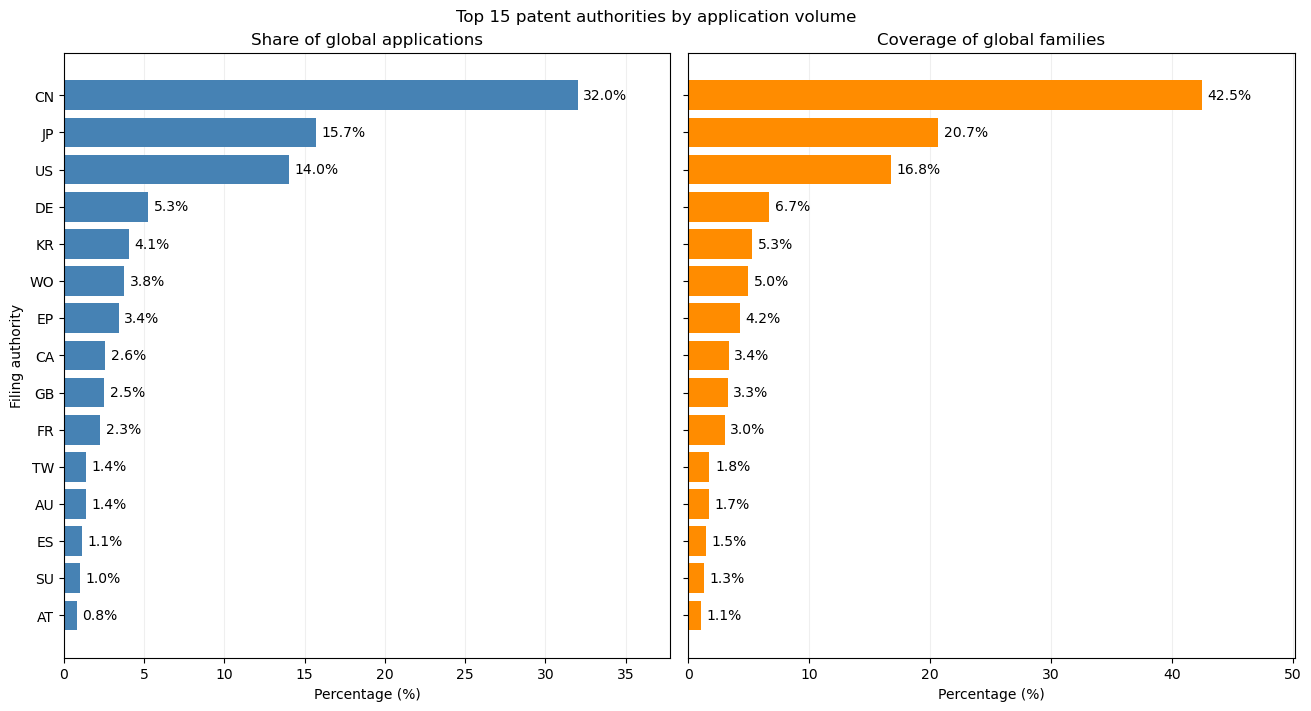

In [10]:
import matplotlib.pyplot as plt

plot_df = (
    df_authorities
    .nlargest(15, "application_count")
    .sort_values("application_count")
)

fig, axes = plt.subplots(
    1, 2, figsize=(13, 7), sharey=True,
    constrained_layout=True
)

for ax, column, title, color in [
    (axes[0], "global_applications_pct", "Share of global applications", "steelblue"),
    (axes[1], "global_families_pct", "Coverage of global families", "darkorange"),
]:
    bars = ax.barh(plot_df["appln_auth"], plot_df[column], color=color)
    ax.bar_label(bars, fmt="%.1f%%", padding=4)
    ax.set_title(title)
    ax.set_xlabel("Percentage (%)")
    ax.margins(x=0.18)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Filing authority")
fig.suptitle("Top 15 patent authorities by application volume")

plt.show()

In [11]:
# Seasrching for a specefic patent
import pandas as pd
from IPython.display import display

from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS209_APPLN_IPC,
    TLS211_PAT_PUBLN,
    TLS224_APPLN_CPC,
    TLS231_INPADOC_LEGAL_EVENT,
)
from functools import lru_cache



PUB_AUTH = "US"
PUB_NUMBER = "11334155"
PUB_KIND = "B2"

# 1. Find the publication and its application
q_patent = (
    db.query(
        TLS211_PAT_PUBLN.pat_publn_id,
        TLS211_PAT_PUBLN.publn_auth,
        TLS211_PAT_PUBLN.publn_nr,
        TLS211_PAT_PUBLN.publn_kind,
        TLS211_PAT_PUBLN.publn_date,
        TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_nr,
        TLS201_APPLN.appln_filing_date,
        TLS201_APPLN.earliest_filing_date,
        TLS201_APPLN.granted,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.nb_citing_docdb_fam,
    )
    .select_from(TLS211_PAT_PUBLN)
    .join(
        TLS201_APPLN,
        TLS211_PAT_PUBLN.appln_id == TLS201_APPLN.appln_id,
    )
    .filter(
        TLS211_PAT_PUBLN.publn_auth == PUB_AUTH,
        TLS211_PAT_PUBLN.publn_nr == PUB_NUMBER,
        TLS211_PAT_PUBLN.publn_kind == PUB_KIND,
    )
)

df_patent = patstat.df(q_patent)

if df_patent.empty:
    print("Publication not found. If using TEST, try PROD.")

else:
    APPLN_ID = int(df_patent.iloc[0]["appln_id"])
    FAMILY_ID = int(df_patent.iloc[0]["docdb_family_id"])

    # 2. Titles
    q_titles = (
        db.query(
            TLS202_APPLN_TITLE.appln_title_lg,
            TLS202_APPLN_TITLE.appln_title,
        )
        .filter(TLS202_APPLN_TITLE.appln_id == APPLN_ID)
    )

    # 3. Abstracts
    q_abstracts = (
        db.query(
            TLS203_APPLN_ABSTR.appln_abstract_lg,
            TLS203_APPLN_ABSTR.appln_abstract,
        )
        .filter(TLS203_APPLN_ABSTR.appln_id == APPLN_ID)
    )

    # 4. Applicants and inventors
    q_people = (
        db.query(
            TLS206_PERSON.person_name,
            TLS206_PERSON.psn_name,
            TLS206_PERSON.person_ctry_code,
            TLS207_PERS_APPLN.applt_seq_nr,
            TLS207_PERS_APPLN.invt_seq_nr,
        )
        .select_from(TLS207_PERS_APPLN)
        .join(
            TLS206_PERSON,
            TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id,
        )
        .filter(TLS207_PERS_APPLN.appln_id == APPLN_ID)
    )

    # 5. CPC and IPC classifications
    q_cpc = (
        db.query(TLS224_APPLN_CPC.cpc_class_symbol)
        .filter(TLS224_APPLN_CPC.appln_id == APPLN_ID)
        .distinct()
        .order_by(TLS224_APPLN_CPC.cpc_class_symbol)
    )

    q_ipc = (
        db.query(TLS209_APPLN_IPC.ipc_class_symbol)
        .filter(TLS209_APPLN_IPC.appln_id == APPLN_ID)
        .distinct()
        .order_by(TLS209_APPLN_IPC.ipc_class_symbol)
    )

    # 6. Publications of the same application
    q_publications = (
        db.query(
            TLS211_PAT_PUBLN.publn_auth,
            TLS211_PAT_PUBLN.publn_nr,
            TLS211_PAT_PUBLN.publn_kind,
            TLS211_PAT_PUBLN.publn_date,
            TLS211_PAT_PUBLN.publn_first_grant,
        )
        .filter(TLS211_PAT_PUBLN.appln_id == APPLN_ID)
        .order_by(TLS211_PAT_PUBLN.publn_date)
    )

    # 7. Applications in the same DOCDB family
    q_family = (
        db.query(
            TLS201_APPLN.appln_id,
            TLS201_APPLN.appln_auth,
            TLS201_APPLN.appln_nr,
            TLS201_APPLN.appln_filing_date,
            TLS201_APPLN.granted,
        )
        .filter(
            TLS201_APPLN.docdb_family_id == FAMILY_ID,
            TLS201_APPLN.docdb_family_id > 0,
        )
        .order_by(TLS201_APPLN.appln_filing_date)
    )

    # 8. Legal events for this application
    q_events = (
        db.query(
            TLS231_INPADOC_LEGAL_EVENT.event_seq_nr,
            TLS231_INPADOC_LEGAL_EVENT.event_auth,
            TLS231_INPADOC_LEGAL_EVENT.event_code,
            TLS231_INPADOC_LEGAL_EVENT.event_effective_date,
            TLS231_INPADOC_LEGAL_EVENT.event_text,
            TLS231_INPADOC_LEGAL_EVENT.fee_country,
            TLS231_INPADOC_LEGAL_EVENT.fee_payment_date,
        )
        .filter(TLS231_INPADOC_LEGAL_EVENT.appln_id == APPLN_ID)
        .order_by(TLS231_INPADOC_LEGAL_EVENT.event_seq_nr)
    )

    # Execute and keep the results for later use
    patent_data = {"Publication and application": df_patent}

    for label, query in [
        ("Titles", q_titles),
        ("Abstracts", q_abstracts),
        ("Applicants and inventors", q_people),
        ("CPC classifications", q_cpc),
        ("IPC classifications", q_ipc),
        ("Publications", q_publications),
        ("DOCDB family", q_family),
        ("Legal events", q_events),
    ]:
        patent_data[label] = patstat.df(query)

    # Display everything
    with pd.option_context(
        "display.max_colwidth", None,
        "display.max_columns", None,
        "display.max_rows", None,
    ):
        for label, result in patent_data.items():
            print(f"\n{label.upper()} ({len(result)} rows)")
            display(result.T if label == "Publication and application" else result)


PUBLICATION AND APPLICATION (1 rows)


,0
pat_publn_id,572478040
publn_auth,US
publn_nr,11334155
publn_kind,B2
publn_date,2022-05-17
appln_id,553590388
appln_nr,201917059223
appln_filing_date,2019-04-25
earliest_filing_date,2018-06-06
granted,Y



TITLES (1 rows)


,appln_title_lg,appln_title
0,en,"Smart glasses, method and device for tracking eyeball trajectory, and storage medium"



ABSTRACTS (1 rows)


...

,publn_auth,publn_nr,publn_kind,publn_date,publn_first_grant
0,US,2021208675,A1,2021-07-08,N
1,US,11334155,B2,2022-05-17,Y



DOCDB FAMILY (6 rows)


,appln_id,appln_auth,appln_nr,appln_filing_date,granted
0,502263924,CN,201810574484,2018-06-06,Y
1,523513133,EP,19815087,2019-04-25,Y
2,553590388,US,201917059223,2019-04-25,Y
3,523487178,WO,2019084232,2019-04-25,Y
4,545011590,AU,2019282933,2019-04-25,Y
5,557436284,JP,2020564920,2019-04-25,Y



LEGAL EVENTS (9 rows)


,event_seq_nr,event_auth,event_code,event_effective_date,event_text,fee_country,fee_payment_date
0,1,US,FEPP,9999-12-31,ENTITY STATUS SET TO UNDISCOUNTED (ORIGINAL EVENT CODE: BIG.); ENTITY STATUS OF PATENT OWNER: SMALL ENTITY,,9999-12-31
1,2,US,FEPP,9999-12-31,ENTITY STATUS SET TO SMALL (ORIGINAL EVENT CODE: SMAL); ENTITY STATUS OF PATENT OWNER: SMALL ENTITY,,9999-12-31
2,3,US,STPP,9999-12-31,DOCKETED NEW CASE - READY FOR EXAMINATION,,9999-12-31
3,4,US,STPP,9999-12-31,NON FINAL ACTION MAILED,,9999-12-31
4,5,US,STPP,9999-12-31,RESPONSE TO NON-FINAL OFFICE ACTION ENTERED AND FORWARDED TO EXAMINER,,9999-12-31
5,6,US,STPP,9999-12-31,NOTICE OF ALLOWANCE MAILED -- APPLICATION RECEIVED IN OFFICE OF PUBLICATIONS,,9999-12-31
6,7,US,STPP,9999-12-31,PUBLICATIONS -- ISSUE FEE PAYMENT VERIFIED,,9999-12-31
7,8,US,STCF,9999-12-31,PATENTED CASE,,9999-12-31
8,9,US,MAFP,9999-12-31,,,9999-12-31


# trial sbert

In [13]:
%pip install -q rank-bm25 sentence-transformers umap-learn

Note: you may need to restart the kernel to use updated packages.


In [65]:
import re
from datetime import date
import matplotlib.pyplot as plt
import numpy as np
import umap
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

In [ ]:
import numpy as np
from sqlalchemy import func
from sentence_transformers import SentenceTransformer

from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS211_PAT_PUBLN,
    TLS224_APPLN_CPC,
)

# ---------------- Configuration ----------------

REFERENCE_AUTH = "US"
REFERENCE_NUMBER = "11334155"
REFERENCE_KIND = "B2"

SBERT_MODEL = "graziasveva93/sbert-adapt-ub"

TITLE_WEIGHT = 0.3
ABSTRACT_WEIGHT = 0.7
TOP_K = 20

# Uses the tutorial's existing patstat and db objects.
# Use PatstatClient(env="PROD") in its connection cell for full coverage.


# ---------------- Common query ----------------

def query_text():
    """Applications with an English title and abstract."""
    return (
        db.query(
            TLS201_APPLN.appln_id,
            TLS201_APPLN.docdb_family_id,
            TLS201_APPLN.appln_auth,
            TLS201_APPLN.appln_nr,
            TLS201_APPLN.appln_filing_date,
            TLS202_APPLN_TITLE.appln_title,
            TLS203_APPLN_ABSTR.appln_abstract,
        )
        .select_from(TLS201_APPLN)
        .join(
            TLS202_APPLN_TITLE,
            TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id,
        )
        .join(
            TLS203_APPLN_ABSTR,
            TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id,
        )
        .filter(
            TLS202_APPLN_TITLE.appln_title_lg == "en",
            TLS203_APPLN_ABSTR.appln_abstract_lg == "en",
            func.length(func.trim(TLS202_APPLN_TITLE.appln_title)) > 0,
            func.length(func.trim(TLS203_APPLN_ABSTR.appln_abstract)) > 0,
        )
    )


# ---------------- Reference patent ----------------

q_reference = (
    query_text()
    .join(
        TLS211_PAT_PUBLN,
        TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id,
    )
    .filter(
        TLS211_PAT_PUBLN.publn_auth == REFERENCE_AUTH,
        TLS211_PAT_PUBLN.publn_nr == REFERENCE_NUMBER,
        TLS211_PAT_PUBLN.publn_kind == REFERENCE_KIND,
    )
    .distinct()
)

reference_df = patstat.df(q_reference)

if reference_df.empty:
    raise ValueError(
        "Reference patent with an English title and abstract was not found. "
        "Check that you are using the PROD database."
    )

reference = reference_df.iloc[0]
reference_id = int(reference["appln_id"])
reference_family = int(reference["docdb_family_id"])

print("Reference:", reference["appln_title"])


# ---------------- Candidate patents ----------------

# Exact CPC symbols assigned to the reference application.
reference_cpcs = (
    db.query(TLS224_APPLN_CPC.cpc_class_symbol)
    .filter(TLS224_APPLN_CPC.appln_id == reference_id)
    .distinct()
)

# Subquery avoids multiplying rows when several CPC codes match.
candidate_ids = (
    db.query(TLS224_APPLN_CPC.appln_id)
    .filter(TLS224_APPLN_CPC.cpc_class_symbol.in_(reference_cpcs))
    .distinct()
)

q_candidates = query_text().filter(
    TLS201_APPLN.appln_id.in_(candidate_ids),
    TLS201_APPLN.appln_id != reference_id,
)

if reference_family > 0:
    q_candidates = q_candidates.filter(
        TLS201_APPLN.docdb_family_id != reference_family
    )

candidates = (
    patstat.df(q_candidates)
    .sort_values("appln_id")
    .drop_duplicates("appln_id")
    .reset_index(drop=True)
)

if candidates.empty:
    raise ValueError("No candidates with English titles and abstracts found.")

print(f"Candidate applications: {len(candidates):,}")


# ---------------- SBERT embeddings ----------------

model = SentenceTransformer(SBERT_MODEL)

def embed_texts(texts):
    """
    Split long inputs into non-overlapping token chunks.
    Average chunk embeddings, then normalize each text embedding.
    """
    tokenizer = model.tokenizer
    chunk_size = (
        model.max_seq_length
        - tokenizer.num_special_tokens_to_add(pair=False)
    )

    chunks, owners = [], []

    for i, text in enumerate(texts):
        token_ids = tokenizer.encode(str(text), add_special_tokens=False)

        for start in range(0, len(token_ids), chunk_size):
            chunks.append(
                tokenizer.decode(
                    token_ids[start:start + chunk_size],
                    skip_special_tokens=True,
                    clean_up_tokenization_spaces=False,
                )
            )
            owners.append(i)

    chunk_embeddings = model.encode(
        chunks,
        batch_size=32,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=True,
    )

    embeddings = np.zeros(
        (len(texts), chunk_embeddings.shape[1]),
        dtype=np.float32,
    )
    np.add.at(embeddings, owners, chunk_embeddings)

    norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
    return embeddings / np.maximum(norms, 1e-12)


title_embeddings = embed_texts(
    [reference["appln_title"]]
    + candidates["appln_title"].tolist()
)

abstract_embeddings = embed_texts(
    [reference["appln_abstract"]]
    + candidates["appln_abstract"].tolist()
)


# ---------------- Similarity and ranking ----------------

candidates["title_similarity"] = (
    title_embeddings[1:] @ title_embeddings[0]
)

candidates["abstract_similarity"] = (
    abstract_embeddings[1:] @ abstract_embeddings[0]
)

candidates["sbert_similarity"] = (
    TITLE_WEIGHT * candidates["title_similarity"]
    + ABSTRACT_WEIGHT * candidates["abstract_similarity"]
)

ranked = candidates.sort_values(
    ["sbert_similarity", "appln_id"],
    ascending=[False, True],
).copy()

# Keep the highest-scoring application from each known family.
# Unknown family IDs are treated as separate applications.
ranked["_family_key"] = np.where(
    ranked["docdb_family_id"].fillna(0).gt(0),
    "family_" + ranked["docdb_family_id"].astype(str),
    "application_" + ranked["appln_id"].astype(str),
)

similar_patents = (
    ranked.drop_duplicates("_family_key")
    .drop(columns="_family_key")
    .head(TOP_K)
    .reset_index(drop=True)
)

similar_patents.insert(0, "rank", np.arange(1, len(similar_patents) + 1))

display(similar_patents[
    [
        "rank",
        "appln_id",
        "docdb_family_id",
        "appln_title",
        "title_similarity",
        "abstract_similarity",
        "sbert_similarity",
        "appln_abstract",
    ]
])

Reference: Smart glasses, method and device for tracking eyeball trajectory, and storage medium
Candidate applications: 275,944


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.99k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/8624 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (873 > 512). Running this sequence through the model will result in indexing errors


Batches:   0%|          | 0/8631 [00:00<?, ?it/s]

In [71]:
CANDIDATE_CPC = "G02B 27/0093"       # First CPC
MIN_FILING_DATE = date(1990, 1, 1)  # patents filed from 1990 onwards
ABSTRACT_LANGUAGE = "en"

SBERT_MODEL = "graziasveva93/sbert-adapt-ub"
TOP_N_DISPLAY = 5                   # rows shown in the ranking tables
TOP_K = 100                         # size of the top lists compared in the overlap and the maps
RANDOM_STATE = 42                   # for a reproducible UMAP projection

DAC_DESCRIPTION = """
A pair of smart glasses includes: a frame, a display assembly, an adjustable camera assembly (30), a sensor assembly, and a micro-controller (50). The frame includes a first side frame, a main frame (120) and a second side frame (130) connected in sequence. The main frame is supported in front of the eyes of the wearable device user. The display assembly is fixed on the main frame, and is connected to the micro-controller. The adjustable camera assembly is arranged on the main frame, and is connected to the micro-controller. The sensor assembly is arranged inside the frame, and is connected to the micro-controller. The micro-controller is arranged inside the frame."""

In [72]:
q_candidates = (
    db.query(
        *APPLN_COLUMNS,
        TLS202_APPLN_TITLE.appln_title,
        TLS203_APPLN_ABSTR.appln_abstract,
        TLS224_APPLN_CPC.cpc_class_symbol,
    )
    .select_from(TLS201_APPLN)
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
    .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
    .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .filter(
        TLS224_APPLN_CPC.cpc_class_symbol == CANDIDATE_CPC,
        TLS201_APPLN.appln_filing_date >= MIN_FILING_DATE,
        TLS203_APPLN_ABSTR.appln_abstract.isnot(None),
        TLS203_APPLN_ABSTR.appln_abstract_lg == ABSTRACT_LANGUAGE,
    )
    .distinct()
)

candidates = (
    patstat.df(q_candidates)
    .dropna(subset=["appln_abstract"])
    .drop_duplicates(subset=["appln_id"])   # one row per application
    .reset_index(drop=True)
)

print(f"Candidate patents: {len(candidates):,}")
candidates

KeyError: ['appln_abstract']

In [73]:
print(patstat.df(q_candidates))

Empty DataFrame
Columns: []
Index: []
